# 2. 패턴 파악

1단계 일별 주문량(2017-01-05 ~ 2018-08-21, 594일)으로 주문이 언제 많고 적은지 확인
여기서 찾은 패턴을 3단계 예측 모델의 입력 컬럼으로 사용


## 2-1. 요일 패턴

- 1단계 그래프에서 일정한 간격으로 오르내리는 모습이 보여 요일 차이를 의심
- 일별 주문 수를 먼저 구하고 요일별 평균 계산 (바로 count하면 평균이 아닌 총합)
- 블랙프라이데이(11/24) 하루가 금요일 평균을 끌어올릴 수 있어 제외

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# 맥 한글 폰트 설정
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
select
    case weekday
        when '1' then '월'
        when '2' then '화'
        when '3' then '수'
        when '4' then '목'
        when '5' then '금'
        when '6' then '토'
        when '0' then '일'
    end as day_name,
    count(*) as num_days,
    round(avg(cnt), 1) as avg_orders
from (
    select date(order_purchase_timestamp) as order_date,
           strftime('%w', order_purchase_timestamp) as weekday,
           count(*) as cnt
    from orders
    where date(order_purchase_timestamp) between '2017-01-05' and '2018-08-21'
      and date(order_purchase_timestamp) <> '2017-11-24'
    group by order_date
)
group by weekday
"""
weekday_avg = pd.read_sql(query, conn)
conn.close()


print(weekday_avg.shape)

(7, 3)


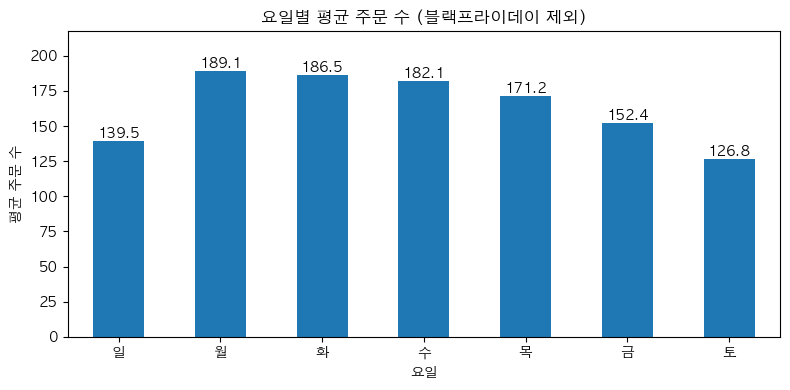

In [6]:
ax = weekday_avg.plot(x='day_name', y='avg_orders', kind='bar',
                      legend=False, figsize=(8, 4), rot=0)
ax.set_title('요일별 평균 주문 수 (블랙프라이데이 제외)')
ax.set_xlabel('요일')
ax.set_ylabel('평균 주문 수')
ax.set_ylim(0, weekday_avg['avg_orders'].max() * 1.15)

for i, v in enumerate(weekday_avg['avg_orders']):
    ax.text(i, v + 2, f'{v}', ha='center')

plt.tight_layout()
plt.show()

| 요일 | 블랙프라이데이 포함 | 제외 |
|---|---|---|
| 월 | 189.1 | 189.1 |
| 화 | 186.5 | 186.5 |
| 수 | 182.1 | 182.1 |
| 목 | 171.2 | 171.2 |
| 금 | 164.4 | 152.4 |
| 토 | 126.8 | 126.8 |
| 일 | 139.5 | 139.5 |

- 월요일 최다, 토요일로 갈수록 감소
- 평일 약 176건, 주말 약 133건으로 주말이 약 25% 적음
- 블랙프라이데이 하루로 금요일 평균이 약 7% 상승 → 이벤트 날은 따로 표시 필요
- 월요일이 가장 많은 이유는 확인 못 함 (주말에 본 상품을 월요일에 주문했을 가능성)

## 2-2. 주별 추세

- 일별은 요일 때문에 흔들려서 주 단위로 묶음
- `strftime('%Y-%W')`는 연말연시에 한 주가 두 해로 나뉘어서, 각 날짜가 속한 주의 월요일 기준으로 묶음
- 86주, 합계 98,390건으로 일별과 일치

In [7]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# 맥 한글 폰트 설정
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

conn = sqlite3.connect('/Users/gon-i/Desktop/olist.db')

query = """
select
    date(order_purchase_timestamp, 'weekday 0', '-6 days') as week_start,
    count(distinct date(order_purchase_timestamp)) as num_days,
    count(*) as weekly_orders
from orders
where date(order_purchase_timestamp) between '2017-01-05' and '2018-08-21'
group by week_start
order by week_start
"""
weekly = pd.read_sql(query, conn)
conn.close()


print(weekly.shape)

(86, 3)


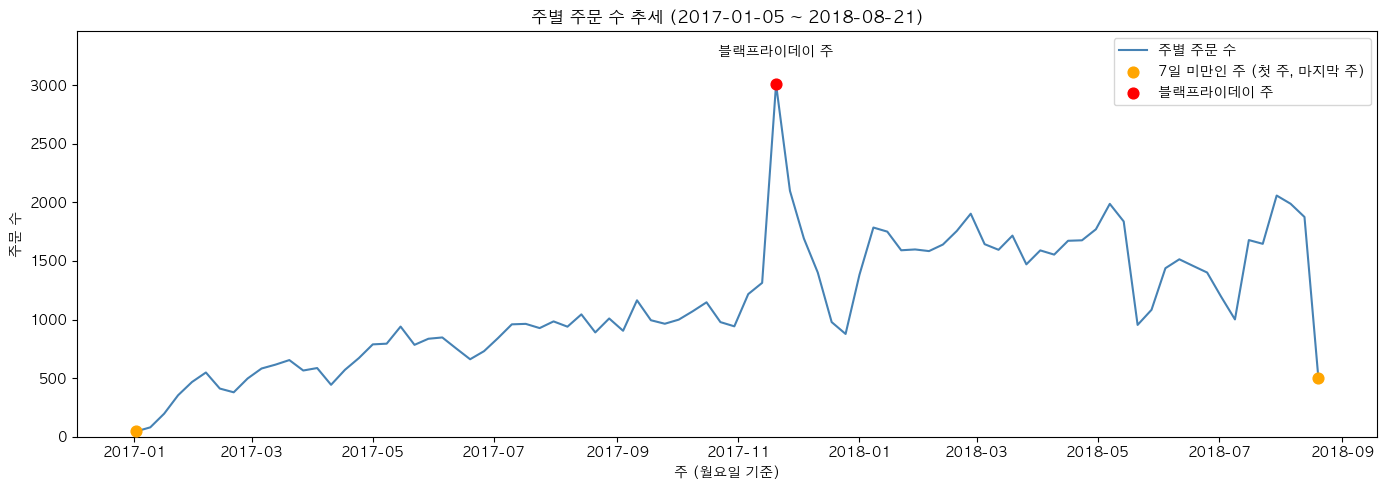

In [9]:
weekly['week_start'] = pd.to_datetime(weekly['week_start'])

full = weekly[weekly['num_days'] == 7]
partial = weekly[weekly['num_days'] < 7]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(weekly['week_start'], weekly['weekly_orders'], color='steelblue', label='주별 주문 수')

ax.scatter(partial['week_start'], partial['weekly_orders'],
           color='orange', s=60, zorder=3, label='7일 미만인 주 (첫 주, 마지막 주)')

# 블랙프라이데이
bf_week = pd.to_datetime('2017-11-20')
bf_value = weekly.loc[weekly['week_start'] == bf_week, 'weekly_orders'].values[0]
ax.scatter(bf_week, bf_value, color='red', s=60, zorder=3, label='블랙프라이데이 주')
ax.annotate('블랙프라이데이 주', xy=(bf_week, bf_value),
            xytext=(bf_week, bf_value * 1.08), ha='center')

ax.set_title('주별 주문 수 추세 (2017-01-05 ~ 2018-08-21)')
ax.set_xlabel('주 (월요일 기준)')
ax.set_ylabel('주문 수')
ax.set_ylim(0, weekly['weekly_orders'].max() * 1.15)
ax.legend()

plt.tight_layout()
plt.show()

- 첫 주(4일), 마지막 주(2일)는 7일이 안 돼서 작게 나옴 → 그래프엔 남기고 색으로 구분, 성장 배수와 모델에서는 제외
- 2017년 1월은 매주 거의 두 배씩 증가 (80 → 197 → 354 → 467), 서비스 초기 구간
- 2017년 동안 꾸준히 증가, 2018년부터는 주별 1,500 ~ 2,000건 사이에서 오르내림
- 블랙프라이데이 주 약 3,000건으로 최고
- 2017년 12월 말, 2018년 5월 말, 2018년 7월 초에 꺼진 구간 있음

## 2-3. 성장 배수

| 비교 방식 | 결과 |
|---|---|
| 처음 4주 vs 마지막 4주 | 약 6.9배 |
| 전년 동기 (3/1 ~ 8/21) | 19,053건 → 39,292건, 2.06배 |

- 처음 4주는 초기 급성장 구간이라 기준이 너무 낮아 성장이 과장됨
- 같은 계절끼리 비교하는 전년 동기 대비로 결정 (2018년 데이터가 8/21에 끝나서 2017년도 8/21까지)

## 2-4. 주문이 줄어든 구간

각 주를 앞 4주 평균과 비교

| 구간 | 가장 낮은 주 | 주문 수 | 앞 4주 평균 | 감소율 |
|---|---|---|---|---|
| 2017 연말연시 | 12-25 | 877 | 1,542.3 | -43.1% |
| 2018년 5월 말 | 05-21 | 954 | 1,817.5 | -47.5% |
| 2018년 7월 초 | 07-09 | 1,001 | 1,392.0 | -28.1% |

- 세 구간 모두 2주 정도 떨어졌다가 바로 회복 → 일시적인 사건으로 판단

### 연말연시
- 앞 4주에 블랙프라이데이 주가 포함돼 감소율이 과장됨
- 블랙프라이데이 직전 4주 평균(1,112.5)으로 다시 보면 12-18주 -12.1%, 12-25주 -21.2%

| 날짜 | 요일 | 주문 수 | 같은 요일 평균 |
|---|---|---|---|
| 12-24 | 일 | 59 | 139.5 |
| 12-25 | 월 | 90 | 189.1 |
| 12-26 | 화 | 168 | 186.5 |
| 12-31 | 일 | 74 | 139.5 |
| 01-01 | 월 | 74 | 189.1 |
| 01-06 | 토 | 216 | 126.8 |

- 크리스마스, 새해 당일에 이틀씩 급감 후 바로 회복
- 12/25, 1/1은 월요일인데 평소 월요일의 절반 이하 → 요일이 아닌 연휴 영향
- 연휴 직후(1/2 ~ 1/7)는 오히려 평소보다 많음, 미뤄진 주문으로 추정

### 2018년 5월 말
- 5/21(월) 206건, 5/22(화) 199건은 정상, 5/23(수)부터 132건으로 떨어져 일주일 넘게 100건대
- 같은 시기 브라질 트럭 운전사 총파업(5/21 시작, 약 열흘). 연료 부족, 도로 봉쇄로 물류 마비
- 피해가 며칠에 걸쳐 커진 게 이틀 늦게 줄어든 것과 맞음, 6월 첫 주부터 회복
- 종료일은 자료마다 5/30, 5/31로 다름

### 2018년 7월 초
- 7/2 ~ 7/5는 정상, 7/6(금) 121건부터 떨어져 7/7(토) 91건, 일주일 정도 낮게 유지
- 2018 월드컵 브라질 경기와 비교 (한국 시간 → 브라질 시간으로 변환)

| 경기 | 브라질 시간 | 주문 |
|---|---|---|
| 조별리그 3경기 | 6/17, 6/22, 6/27 | 정상 |
| 16강 (승) | 7/2(월) | 195, 정상 |
| 8강 (패, 탈락) | 7/6(금) | 121, 감소 시작 |

- 경기 날 대부분은 정상이라 경기 때문이라고 보기 어려움
- 8강 탈락일과 감소 시작이 겹치지만 근거 부족 → 원인 미확인으로 둠

## 한계
- 블랙프라이데이, 연말연시가 한 번씩만 있어 매년 반복되는지는 확인 불가
- 7월 감소 원인 미확인
- 파업, 월드컵 일정은 검색 자료라 공식 자료로 추가 확인 필요
- 구매일 기준이라 실제 입고일과 차이 가능
